# EDA dữ liệu bảng: Adult Census Income

Chương này phân tích thống kê tập Adult **trước khi** tiền xử lý. Mục tiêu là hiểu dữ liệu đủ sâu để mỗi lựa chọn ở chương sau (cách điền giá trị thiếu, cách scale, cách xử lý đa cộng tuyến) đều có căn cứ thống kê.

Ba phân tích bắt buộc theo đề:

1. **Kiểm định phân phối** cho từng thuộc tính số, dùng để chọn phương pháp scale.
2. **Tương quan đa biến** bằng Pearson và Spearman, phát hiện các cặp có nguy cơ đa cộng tuyến.
3. **Dữ liệu thiếu:** trực quan hóa bằng `missingno`, kiểm định Little's MCAR và xác định cơ chế thiếu (MCAR, MAR hay MNAR).

Mọi kết quả số đều được in ra và lưu trong biến Python để tiện kiểm tra lại. Mức ý nghĩa dùng xuyên suốt là $\alpha = 0.05$.

In [1]:
import warnings

import matplotlib.pyplot as plt
import missingno as msno
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor

from utils.config import RANDOM_STATE, set_seed
from utils.data_loader import load_adult

set_seed(RANDOM_STATE)
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

ALPHA = 0.05

## 1. Tổng quan dữ liệu

Trong dữ liệu gốc, giá trị thiếu được ghi bằng ký tự `?`, vì vậy bước đầu tiên là chuyển chúng thành `NaN`.

In [2]:
adult = load_adult().replace("?", np.nan)

TARGET = "income"
NUM_COLS = adult.drop(columns=TARGET).select_dtypes("number").columns.tolist()
CAT_COLS = [c for c in adult.columns if c not in NUM_COLS + [TARGET]]

n_rows, n_cols = adult.shape
n_duplicates = int(adult.duplicated().sum())
print(f"Số dòng: {n_rows:,}, số cột: {n_cols}")
print("Thuộc tính số      :", NUM_COLS)
print("Thuộc tính phân loại:", CAT_COLS)
print(f"Số dòng trùng lặp hoàn toàn: {n_duplicates} ({n_duplicates / n_rows:.3%})")

Số dòng: 32,561, số cột: 15
Thuộc tính số      : ['age', 'fnlwgt', 'education.num', 'capital.gain', 'capital.loss', 'hours.per.week']
Thuộc tính phân loại: ['workclass', 'education', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'native.country']
Số dòng trùng lặp hoàn toàn: 24 (0.074%)


In [3]:
num_summary = adult[NUM_COLS].describe().T
num_summary["skew"] = adult[NUM_COLS].skew()
num_summary["% bằng 0"] = (adult[NUM_COLS] == 0).mean() * 100
num_summary

,count,mean,std,min,25%,50%,75%,max,skew,% bằng 0
age,"32,561.0000",38.5816,13.6404,17.0000,28.0000,37.0000,48.0000,90.0000,0.5587,0.0000
fnlwgt,"32,561.0000","189,778.3665","105,549.9777","12,285.0000","117,827.0000","178,356.0000","237,051.0000","1,484,705.0000",1.4470,0.0000
education.num,"32,561.0000",10.0807,2.5727,1.0000,9.0000,10.0000,12.0000,16.0000,-0.3117,0.0000
capital.gain,"32,561.0000","1,077.6488","7,385.2921",0.0000,0.0000,0.0000,0.0000,"99,999.0000",11.9538,91.6710
capital.loss,"32,561.0000",87.3038,402.9602,0.0000,0.0000,0.0000,0.0000,"4,356.0000",4.5946,95.3349
hours.per.week,"32,561.0000",40.4375,12.3474,1.0000,40.0000,40.0000,45.0000,99.0000,0.2276,0.0000


In [4]:
# Hai đặc điểm bất thường thấy được từ bảng trên
cap_gain_max_count = int((adult["capital.gain"] == 99_999).sum())
cap_gain_max_rich = (adult.loc[adult["capital.gain"] == 99_999, TARGET] == ">50K").mean()
hours_40_ratio = (adult["hours.per.week"] == 40).mean()
print(f"Số dòng có capital.gain = 99999 (giá trị trần): {cap_gain_max_count}, trong đó {cap_gain_max_rich:.0%} có income >50K")
print(f"Tỷ lệ hours.per.week đúng bằng 40: {hours_40_ratio:.2%}")

Số dòng có capital.gain = 99999 (giá trị trần): 159, trong đó 100% có income >50K
Tỷ lệ hours.per.week đúng bằng 40: 46.73%


In [5]:
cat_summary = pd.DataFrame({
    "số giá trị": adult[CAT_COLS + [TARGET]].nunique(),
    "giá trị phổ biến nhất": adult[CAT_COLS + [TARGET]].mode().iloc[0],
    "% giá trị phổ biến nhất": adult[CAT_COLS + [TARGET]].apply(lambda s: s.value_counts(normalize=True).iloc[0] * 100),
    "% thiếu": adult[CAT_COLS + [TARGET]].isna().mean() * 100,
})
cat_summary

,số giá trị,giá trị phổ biến nhất,% giá trị phổ biến nhất,% thiếu
workclass,8,Private,73.8682,5.6386
education,16,HS-grad,32.2502,0.0000
marital.status,7,Married-civ-spouse,45.9937,0.0000
occupation,14,Prof-specialty,13.4774,5.6601
relationship,6,Husband,40.5178,0.0000
race,5,White,85.4274,0.0000
sex,2,Male,66.9205,0.0000
native.country,41,United-States,91.2190,1.7905
income,2,<=50K,75.9190,0.0000


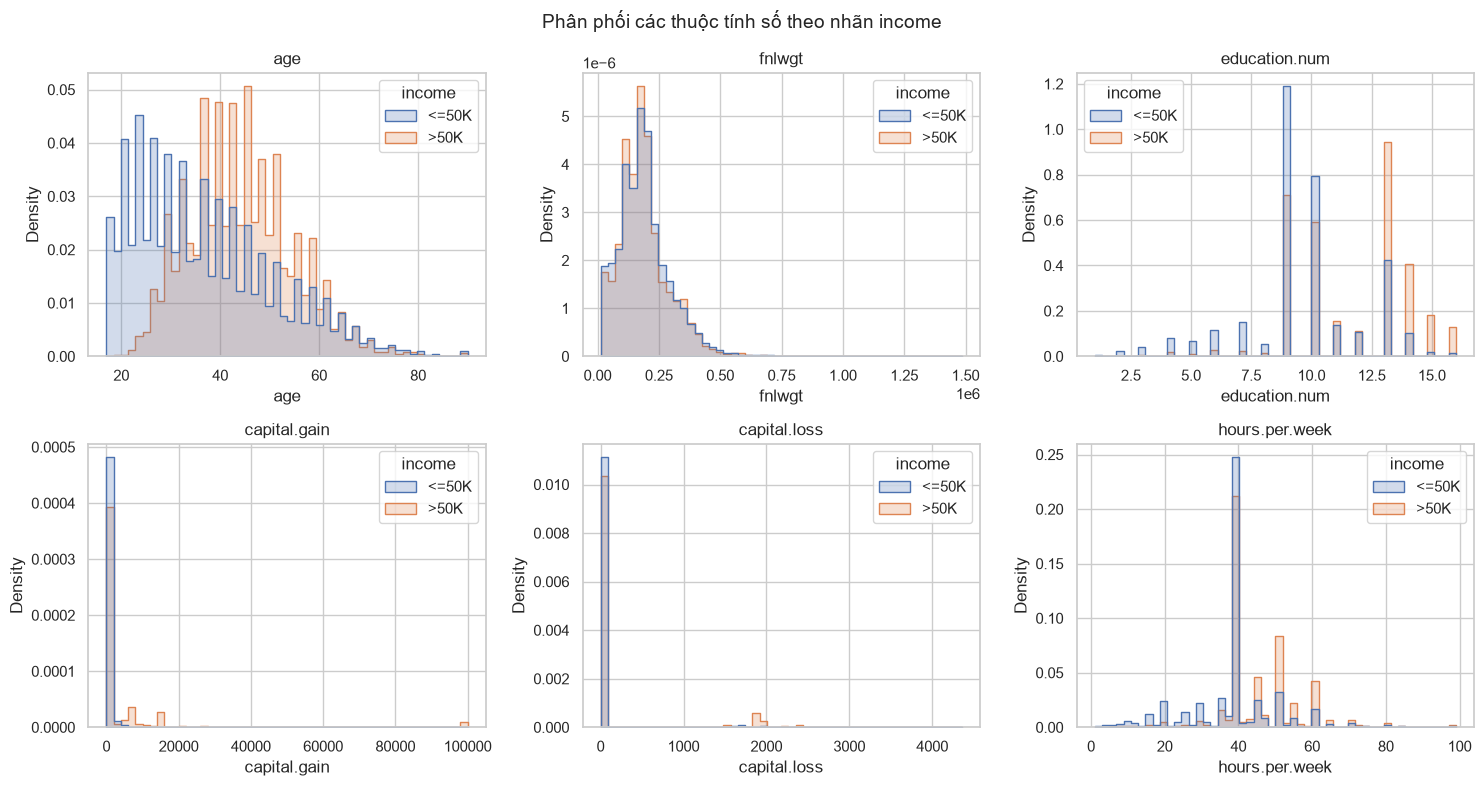

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), NUM_COLS):
    sns.histplot(data=adult, x=col, hue=TARGET, bins=50, kde=False, ax=ax, element="step", stat="density", common_norm=False)
    ax.set_title(col)
fig.suptitle("Phân phối các thuộc tính số theo nhãn income", fontsize=14)
fig.tight_layout()
plt.show()

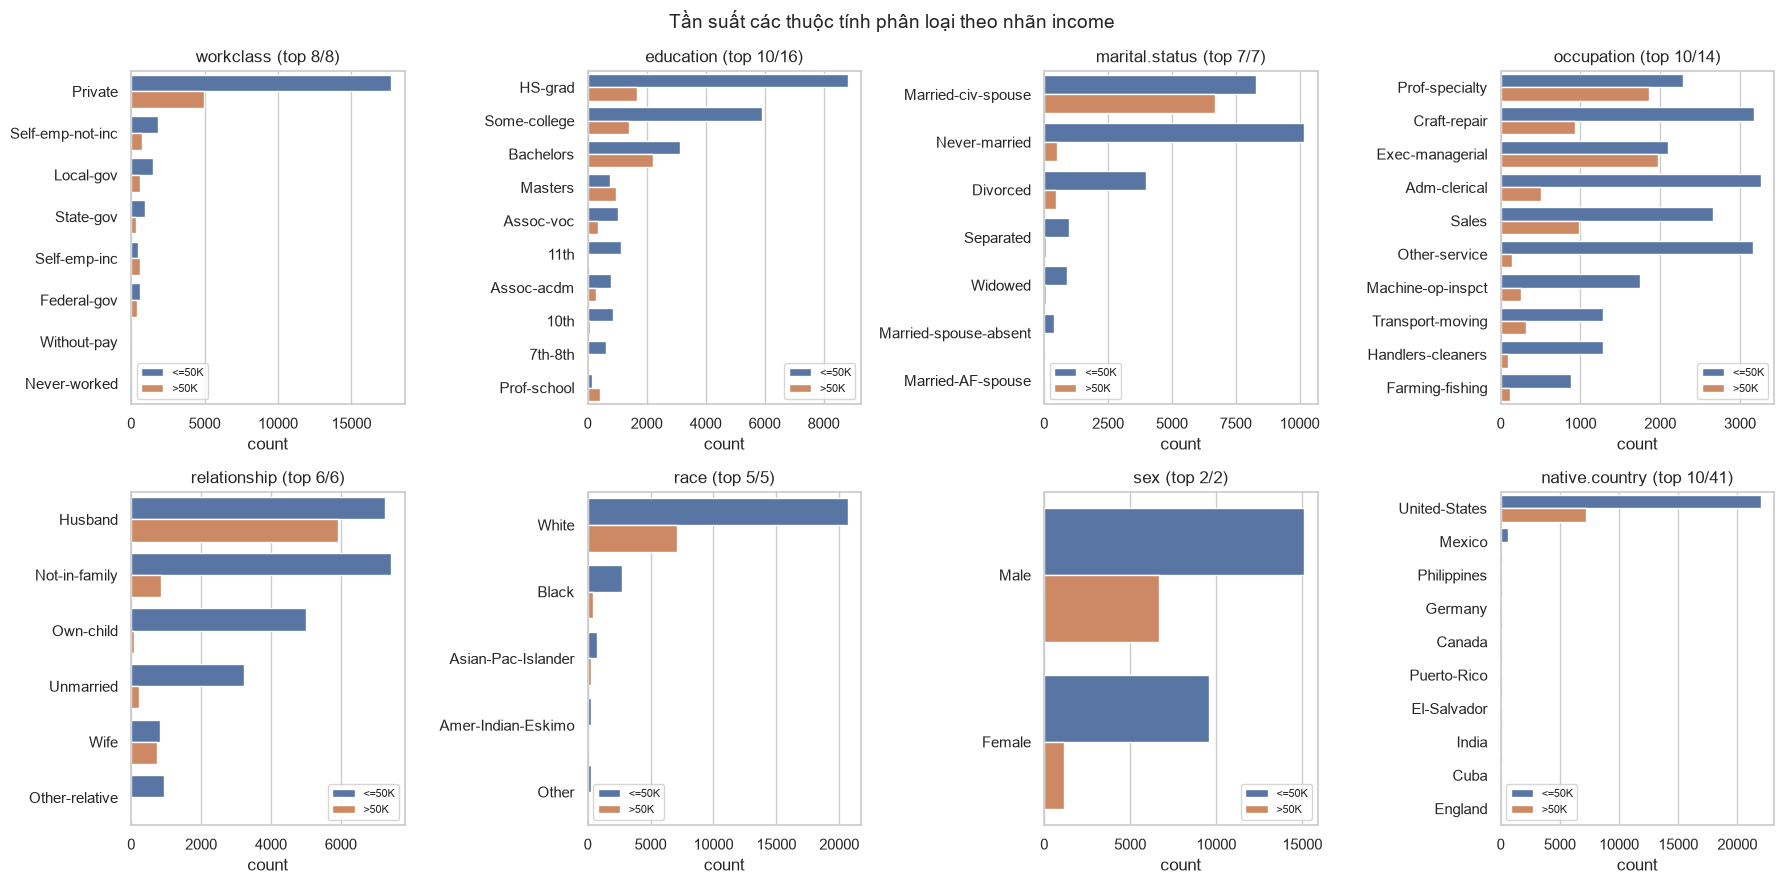

Tỷ lệ nhãn:
 income
<=50K   0.7592
>50K    0.2408
Tỷ lệ lớp đa số / lớp thiểu số: 3.15


In [7]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, col in zip(axes.ravel(), CAT_COLS):
    top = adult[col].value_counts().head(10).index
    sub = adult[adult[col].isin(top)]
    sns.countplot(data=sub, y=col, hue=TARGET, order=top, ax=ax)
    ax.set_title(f"{col} (top {len(top)}/{adult[col].nunique()})")
    ax.set_ylabel("")
    ax.legend(fontsize=8)
fig.suptitle("Tần suất các thuộc tính phân loại theo nhãn income", fontsize=14)
fig.tight_layout()
plt.show()

target_ratio = adult[TARGET].value_counts(normalize=True)
imbalance_ratio = target_ratio.max() / target_ratio.min()
print("Tỷ lệ nhãn:\n", target_ratio.round(4).to_string())
print(f"Tỷ lệ lớp đa số / lớp thiểu số: {imbalance_ratio:.2f}")

### Nhận xét tổng quan

- **Quy mô và chất lượng:** 32.561 dòng, 14 thuộc tính (6 số, 8 phân loại) và nhãn `income`. Có 24 dòng trùng lặp hoàn toàn (0,074%). Vì `fnlwgt` là trọng số mẫu gần như duy nhất cho mỗi người, hai dòng trùng khớp cả `fnlwgt` nhiều khả năng là lỗi nhập trùng. Các dòng này sẽ được loại ở chương tiền xử lý.
- **Hai thuộc tính vốn dồn khối tại 0:** `capital.gain` có 91,7% giá trị bằng 0, `capital.loss` có 95,3%. Riêng `capital.gain` có 159 dòng bằng đúng **99999**, giá trị trần (top-coding) của cuộc điều tra chứ không phải số đo thật. 100% các dòng này có thu nhập >50K. Đây là ngoại lai *có thông tin*, cần cân nhắc kỹ trước khi loại bỏ.
- **`hours.per.week`** có 46,7% giá trị bằng đúng 40 (tuần làm việc tiêu chuẩn), tạo thành một gai nhọn trong phân phối.
- **`fnlwgt`** là trọng số chọn mẫu của Cục Điều tra dân số, không mô tả đặc điểm cá nhân. Hai đường phân phối theo nhãn gần như trùng nhau, nên đây là ứng viên bị loại ở bước chọn đặc trưng.
- **Biến phân loại mất cân bằng mạnh:** `native.country` có 41 giá trị nhưng 91,2% là `United-States`, `race` có 85,4% là `White`. Các mức hiếm sẽ tạo nhiều cột gần như rỗng khi One-Hot. Đây là lý do chương sau thử thêm Binary Encoding và Frequency Encoding.
- **Nhãn mất cân bằng:** tỷ lệ 75,9% / 24,1%, tức 3,15 : 1. Vì vậy cần dùng F1-macro và AUC thay cho accuracy, và chia train/test có phân tầng (stratify).

## 2. Kiểm định phân phối chuẩn

### Lý thuyết

Với mỗi thuộc tính số, ta kiểm định giả thuyết

$$H_0: \text{dữ liệu được lấy mẫu từ phân phối chuẩn} \qquad H_1: \text{không phải phân phối chuẩn}.$$

**Shapiro-Wilk** dùng khi $n \le 5000$:

$$W = \frac{\left(\sum_{i=1}^{n} a_i\, x_{(i)}\right)^2}{\sum_{i=1}^{n} (x_i - \bar{x})^2},$$

trong đó $x_{(i)}$ là thống kê thứ tự và $a_i$ là các hệ số suy từ kỳ vọng thống kê thứ tự của phân phối chuẩn. Với $n > 5000$, xấp xỉ p-value của Shapiro-Wilk không còn chính xác (SciPy cũng cảnh báo điều này).

**D'Agostino-Pearson** dùng khi $n > 5000$. Kiểm định này kết hợp độ lệch (skewness) và độ nhọn (kurtosis):

$$K^2 = Z_1(\sqrt{b_1})^2 + Z_2(b_2)^2 \;\sim\; \chi^2_{2} \text{ dưới } H_0,$$

với $\sqrt{b_1} = \dfrac{m_3}{m_2^{3/2}}$ là skewness mẫu, $b_2 = \dfrac{m_4}{m_2^{2}}$ là kurtosis mẫu ($m_k$ là moment trung tâm bậc $k$), còn $Z_1, Z_2$ là các phép biến đổi đưa hai đại lượng này về phân phối xấp xỉ chuẩn tắc.

Tập Adult có $n = 32\,561 > 5000$, nên **D'Agostino-Pearson là kiểm định chính**. Shapiro-Wilk chạy trên một mẫu con ngẫu nhiên gồm 5000 dòng chỉ để đối chiếu.

**Lưu ý về cỡ mẫu lớn:** khi $n$ rất lớn, kiểm định có lực (power) gần bằng 1 nên một độ lệch rất nhỏ so với phân phối chuẩn cũng bị bác bỏ. Vì vậy, ngoài p-value, ta xét thêm **độ lớn hiệu ứng**: skewness, excess kurtosis và Q-Q plot.

In [8]:
sample_idx = adult.sample(n=5000, random_state=RANDOM_STATE).index

rows = []
for col in NUM_COLS:
    x = adult[col].dropna().to_numpy()
    k2, p_dag = stats.normaltest(x)
    w, p_sw = stats.shapiro(adult.loc[sample_idx, col])
    rows.append({
        "thuộc tính": col,
        "n": len(x),
        "skewness": stats.skew(x),
        "excess kurtosis": stats.kurtosis(x),
        "K² (D'Agostino)": k2,
        "p (D'Agostino)": p_dag,
        "W (Shapiro, n=5000)": w,
        "p (Shapiro)": p_sw,
        "kết luận": "chuẩn" if p_dag > ALPHA else "không chuẩn",
    })
normality_results = pd.DataFrame(rows).set_index("thuộc tính")
normality_results.style.format({
    "skewness": "{:.3f}", "excess kurtosis": "{:.3f}", "K² (D'Agostino)": "{:,.1f}",
    "p (D'Agostino)": "{:.2e}", "W (Shapiro, n=5000)": "{:.4f}", "p (Shapiro)": "{:.2e}",
})

,n,skewness,excess kurtosis,K² (D'Agostino),p (D'Agostino),"W (Shapiro, n=5000)",p (Shapiro),kết luận
thuộc tính,,,,,,,,
age,32561,0.559,-0.166,"1,526.0",0.00e+00,0.9654,4.78e-33,không chuẩn
fnlwgt,32561,1.447,6.218,"10,662.5",0.00e+00,0.9087,1.07e-47,không chuẩn
education.num,32561,-0.312,0.623,817.2,3.59e-178,0.9245,1.32e-44,không chuẩn
capital.gain,32561,11.953,154.775,"55,096.6",0.00e+00,0.1169,6.24e-93,không chuẩn
capital.loss,32561,4.594,20.373,"29,331.4",0.00e+00,0.2102,2.40e-90,không chuẩn
hours.per.week,32561,0.228,2.916,"2,508.9",0.00e+00,0.8800,2.49e-52,không chuẩn


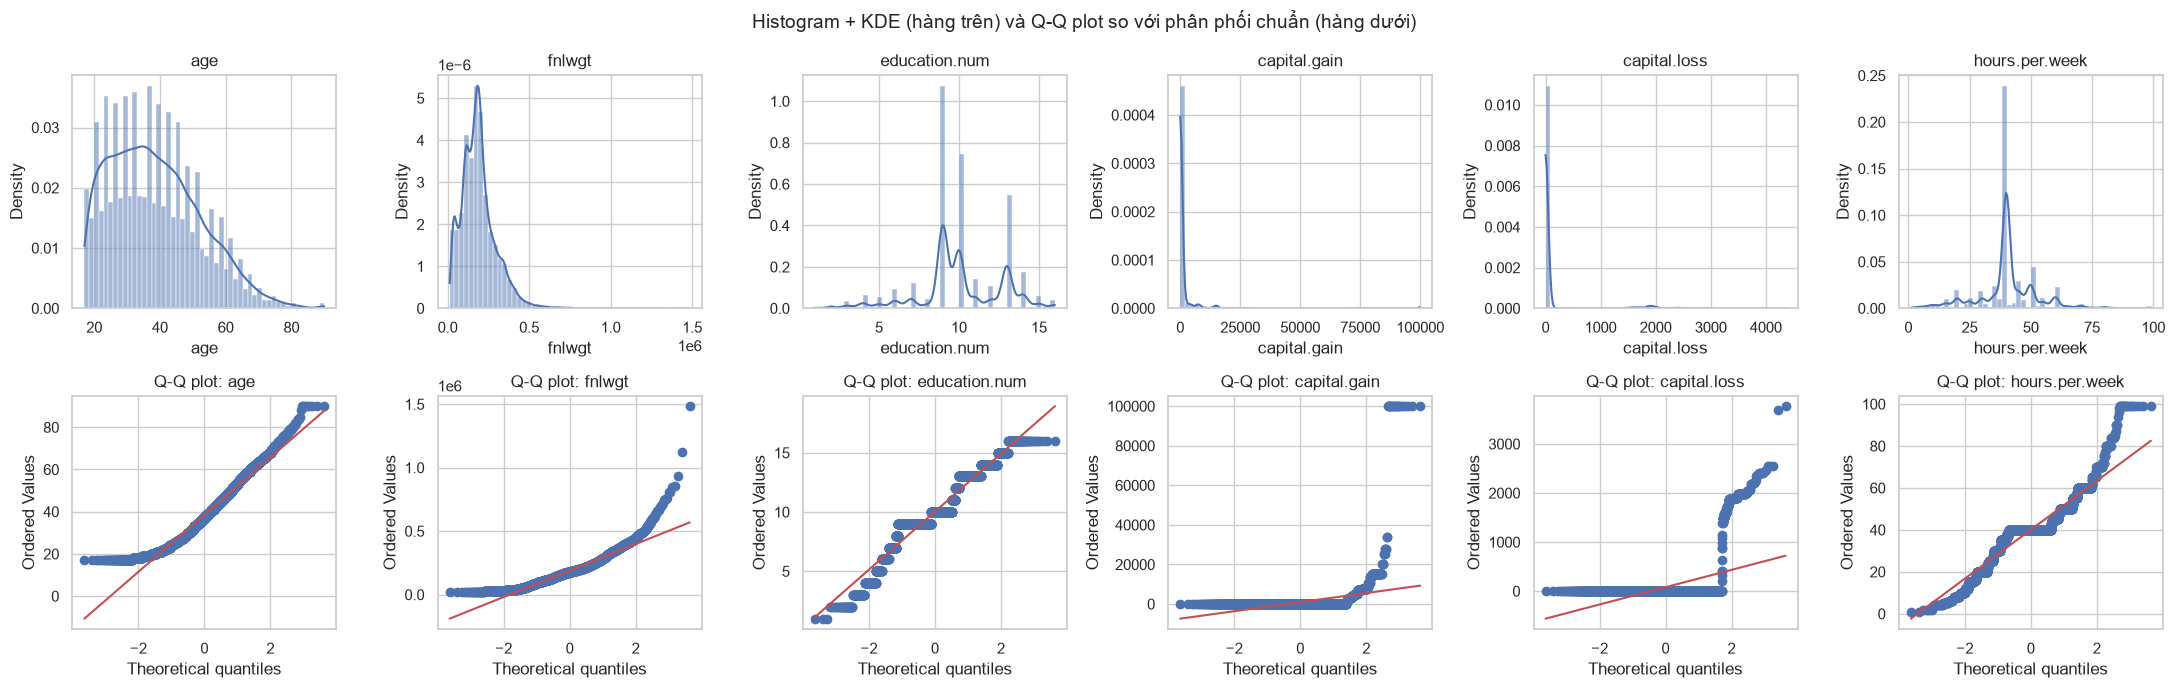

In [9]:
fig, axes = plt.subplots(2, 6, figsize=(22, 7))
for i, col in enumerate(NUM_COLS):
    sns.histplot(adult[col], bins=50, kde=True, ax=axes[0, i], stat="density")
    axes[0, i].set_title(col)
    stats.probplot(adult.loc[sample_idx, col], dist="norm", plot=axes[1, i])
    axes[1, i].set_title(f"Q-Q plot: {col}")
fig.suptitle("Histogram + KDE (hàng trên) và Q-Q plot so với phân phối chuẩn (hàng dưới)", fontsize=14)
fig.tight_layout()
plt.show()

### Từ kết quả kiểm định đến lựa chọn phương pháp scale

Kết quả kiểm định được chuyển thành đề xuất scale theo các quy tắc sau:

| Tình huống | Phương pháp đề xuất | Lý do |
|---|---|---|
| Phân phối chuẩn | Z-score (StandardScaler) | Giả định chuẩn được thỏa, $z = (x-\mu)/\sigma$ giữ nguyên hình dạng phân phối |
| Không chuẩn, lệch vừa phải ($\lvert \text{skew} \rvert < 1$), ít ngoại lai | Min-Max hoặc Z-score | Phân phối gần đối xứng, không bị ngoại lai kéo lệch |
| Không chuẩn, lệch mạnh hoặc nhiều ngoại lai | Robust Scaling, $(x - \text{median})/\text{IQR}$ | Median và IQR không bị ngoại lai chi phối |
| Không chuẩn, dồn khối tại 0 (zero-inflated) | $\log(1+x)$ rồi Quantile Transform, hoặc tách thêm biến nhị phân "có/không" | IQR có thể bằng 0 nên Robust Scaling không dùng được |

Tỷ lệ ngoại lai được ước lượng sơ bộ bằng quy tắc IQR ($x < Q_1 - 1.5\,\text{IQR}$ hoặc $x > Q_3 + 1.5\,\text{IQR}$). Phát hiện ngoại lai đầy đủ sẽ làm ở chương sau.

In [10]:
def iqr_outlier_ratio(s: pd.Series) -> float:
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return float(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean())


def recommend_scaler(col: str) -> tuple[str, str]:
    s = adult[col]
    r = normality_results.loc[col]
    zero_ratio = (s == 0).mean()
    q1, q3 = s.quantile([0.25, 0.75])
    if r["kết luận"] == "chuẩn":
        return "Z-score", "đạt giả định chuẩn"
    if zero_ratio > 0.5 and q3 - q1 == 0:
        return "log1p + Quantile / biến nhị phân", f"{zero_ratio:.0%} giá trị bằng 0, IQR = 0"
    if abs(r["skewness"]) >= 1 or iqr_outlier_ratio(s) > 0.05:
        return "Robust Scaling", f"lệch {r['skewness']:.2f}, ngoại lai IQR {iqr_outlier_ratio(s):.1%}"
    return "Min-Max / Z-score", f"lệch nhẹ {r['skewness']:.2f}, ngoại lai IQR {iqr_outlier_ratio(s):.1%}"


scaling_plan = pd.DataFrame(
    [(c, *recommend_scaler(c)) for c in NUM_COLS],
    columns=["thuộc tính", "đề xuất scale", "căn cứ"],
).set_index("thuộc tính")
scaling_plan

,đề xuất scale,căn cứ
thuộc tính,,
age,Min-Max / Z-score,"lệch nhẹ 0.56, ngoại lai IQR 0.4%"
fnlwgt,Robust Scaling,"lệch 1.45, ngoại lai IQR 3.0%"
education.num,Min-Max / Z-score,"lệch nhẹ -0.31, ngoại lai IQR 3.7%"
capital.gain,log1p + Quantile / biến nhị phân,"92% giá trị bằng 0, IQR = 0"
capital.loss,log1p + Quantile / biến nhị phân,"95% giá trị bằng 0, IQR = 0"
hours.per.week,Robust Scaling,"lệch 0.23, ngoại lai IQR 27.7%"


### Nhận xét kiểm định phân phối

**Kết quả kiểm định:** cả 6 thuộc tính số đều bác bỏ $H_0$ ở cả hai kiểm định. p-value của D'Agostino-Pearson bằng 0 do tràn số dưới (underflow), riêng `education.num` là $3.6\times10^{-178}$. Shapiro-Wilk trên mẫu con 5000 dòng cho cùng kết luận ($p < 10^{-32}$). **Không thuộc tính nào có phân phối chuẩn.**

Vì $n$ lớn khiến kiểm định bác bỏ cả những sai lệch rất nhỏ, ta xét thêm độ lớn hiệu ứng (skewness, excess kurtosis) và Q-Q plot:

| Thuộc tính | Skew / Kurtosis | Hình dạng thực tế | Mức độ xa phân phối chuẩn |
|---|---|---|---|
| `age` | 0,56 / −0,17 | Lệch phải nhẹ, bị chặn dưới tại 17 tuổi (đuôi trái phẳng trên Q-Q plot) | Gần chuẩn nhất |
| `education.num` | −0,31 / 0,62 | **Rời rạc, có thứ tự** với 16 mức; Q-Q plot có dạng bậc thang | Kiểm định chuẩn ít ý nghĩa với biến rời rạc |
| `hours.per.week` | 0,23 / 2,92 | Gần đối xứng nhưng **nhọn** (leptokurtic) do 46,7% bằng 40 | Trung bình |
| `fnlwgt` | 1,45 / 6,22 | Lệch phải, đuôi dài, có dạng gần log-chuẩn | Xa |
| `capital.loss` | 4,59 / 20,37 | Dồn khối tại 0 (zero-inflated) | Rất xa |
| `capital.gain` | 11,95 / 154,78 | Dồn khối tại 0 và có giá trị trần 99999 | Rất xa |

**Hệ quả cho việc chọn phương pháp scale:**

- Z-score giả định dữ liệu gần chuẩn, nên **không phù hợp làm lựa chọn mặc định** cho bất kỳ thuộc tính nào ở đây. Phép biến đổi không làm thay đổi hình dạng phân phối, nên các đuôi dài vẫn còn nguyên.
- `age` và `education.num` lệch nhẹ, có miền giá trị bị chặn và ít ngoại lai, nên dùng **Min-Max** là hợp lý. `education.num` vốn là thang thứ tự, nên Min-Max giữ đúng khoảng cách giữa các bậc.
- `fnlwgt` lệch mạnh và có ngoại lai, nên dùng **Robust Scaling**. Có thể biến đổi $\log$ trước để kéo đuôi về gần đối xứng.
- `capital.gain` và `capital.loss` có $Q_1 = Q_3 = 0$, tức **IQR = 0**, nên Robust Scaling suy biến (scikit-learn khi đó chỉ trừ median và không chia). Hướng xử lý phù hợp là $\log(1+x)$ kèm một **biến nhị phân** `has_gain` / `has_loss`, hoặc Quantile Transform.
- `hours.per.week`: quy tắc tự động đề xuất Robust Scaling vì 27,7% giá trị nằm ngoài khoảng IQR. Đây là **hệ quả của IQR quá hẹp** (từ 40 đến 45, chỉ rộng 5 giờ) chứ không phải 27,7% là ngoại lai thật. Khi IQR nhỏ như vậy, Robust Scaling sẽ **khuếch đại** khoảng cách của các giá trị như 20 hay 60 giờ. Chương sau sẽ so sánh trực tiếp Robust Scaling với Quantile Transform cho thuộc tính này.

Bảng `scaling_plan` là giả thuyết ban đầu. Chương tiền xử lý sẽ kiểm chứng giả thuyết này bằng violin plot và kiểm định Levene trên cả 4 phương pháp scale.

## 3. Tương quan đa biến

### Lý thuyết

**Hệ số Pearson** đo mức độ quan hệ **tuyến tính**:

$$r_{XY} = \frac{\sum_i (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_i (x_i - \bar{x})^2}\,\sqrt{\sum_i (y_i - \bar{y})^2}}.$$

Hệ số này nhạy với ngoại lai và giả định quan hệ tuyến tính.

**Hệ số Spearman** là hệ số Pearson tính trên **thứ hạng**, nên đo quan hệ **đơn điệu** và bền vững với ngoại lai. Khi không có hạng trùng:

$$\rho_{XY} = 1 - \frac{6\sum_i d_i^2}{n(n^2-1)}, \qquad d_i = \operatorname{rank}(x_i) - \operatorname{rank}(y_i).$$

Một cặp có $\lvert r \rvert > 0.9$ được xem là có nguy cơ **đa cộng tuyến** mạnh: hai biến mang gần như cùng một thông tin, làm hệ số của mô hình tuyến tính không ổn định. Để phát hiện cả đa cộng tuyến giữa **nhiều** biến (không chỉ từng cặp), ta tính thêm **VIF**:

$$\text{VIF}_j = \frac{1}{1 - R_j^2},$$

với $R_j^2$ là hệ số xác định khi hồi quy biến $j$ theo tất cả các biến còn lại. VIF $> 10$ thường được xem là đa cộng tuyến nghiêm trọng.

Pearson và Spearman chỉ áp dụng cho biến số. Với **biến phân loại**, ta dùng **Cramér's V**, dựa trên thống kê $\chi^2$ của bảng chéo $r \times c$:

$$V = \sqrt{\frac{\chi^2 / n}{\min(r-1,\, c-1)}} \in [0, 1].$$

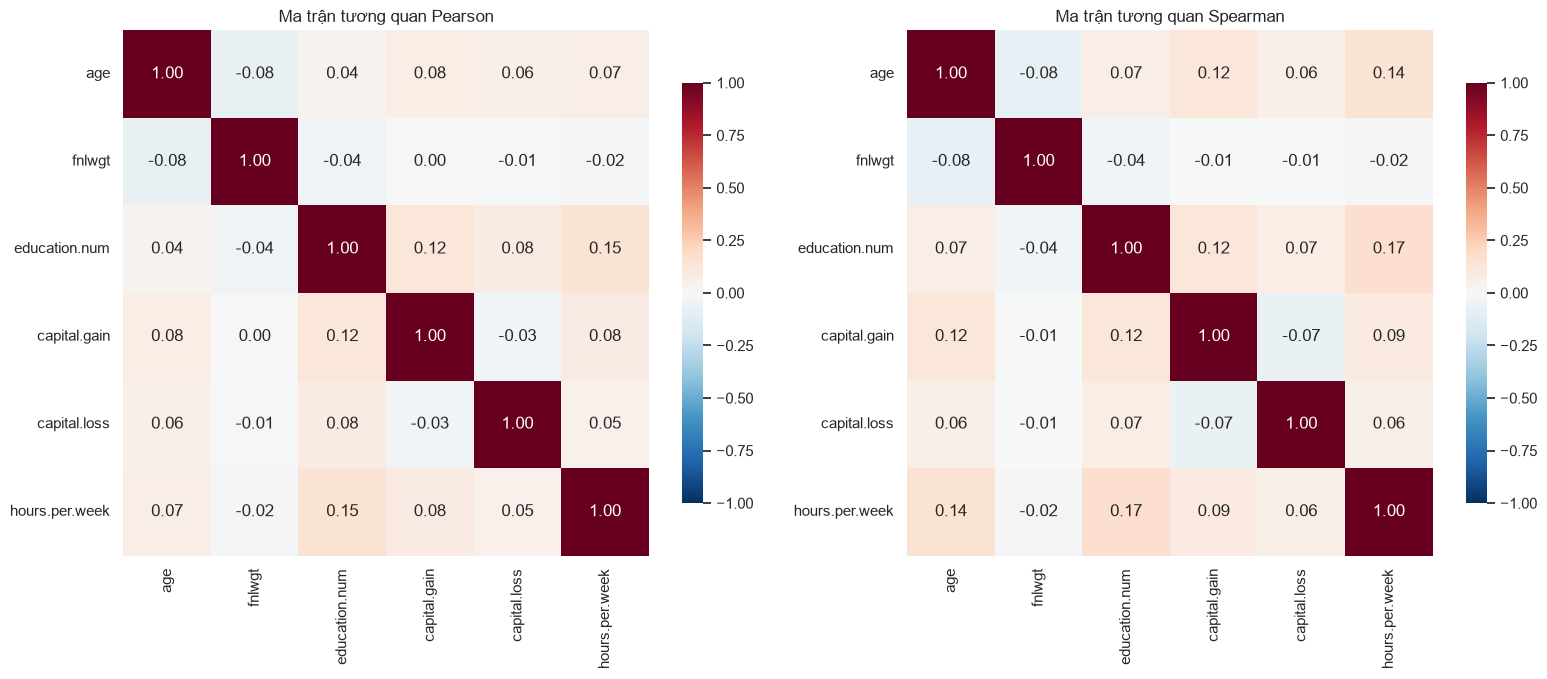

In [11]:
pearson_corr = adult[NUM_COLS].corr(method="pearson")
spearman_corr = adult[NUM_COLS].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, (name, m) in zip(axes, [("Pearson", pearson_corr), ("Spearman", spearman_corr)]):
    sns.heatmap(m, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=ax, cbar_kws={"shrink": 0.8})
    ax.set_title(f"Ma trận tương quan {name}")
fig.tight_layout()
plt.show()

In [12]:
def corr_pairs(m: pd.DataFrame, name: str) -> pd.DataFrame:
    iu = np.triu_indices_from(m, k=1)
    return pd.DataFrame({
        "biến 1": m.index[iu[0]], "biến 2": m.columns[iu[1]], name: m.values[iu],
    })


corr_pair_table = corr_pairs(pearson_corr, "Pearson").merge(
    corr_pairs(spearman_corr, "Spearman"), on=["biến 1", "biến 2"])
corr_pair_table["|Pearson - Spearman|"] = (corr_pair_table["Pearson"] - corr_pair_table["Spearman"]).abs()
corr_pair_table = corr_pair_table.reindex(
    corr_pair_table[["Pearson", "Spearman"]].abs().max(axis=1).sort_values(ascending=False).index)

strong_pairs = corr_pair_table[(corr_pair_table[["Pearson", "Spearman"]].abs() > 0.9).any(axis=1)]
print(f"Số cặp biến số có |r| > 0.9: {len(strong_pairs)}")
print(f"|r| lớn nhất (Pearson) : {corr_pair_table['Pearson'].abs().max():.4f}")
print(f"|ρ| lớn nhất (Spearman): {corr_pair_table['Spearman'].abs().max():.4f}")
corr_pair_table.head(8)

Số cặp biến số có |r| > 0.9: 0
|r| lớn nhất (Pearson) : 0.1481
|ρ| lớn nhất (Spearman): 0.1672


,biến 1,biến 2,Pearson,Spearman,|Pearson - Spearman|
11,education.num,hours.per.week,0.1481,0.1672,0.0191
4,age,hours.per.week,0.0688,0.1429,0.0742
2,age,capital.gain,0.0777,0.1249,0.0473
9,education.num,capital.gain,0.1226,0.1191,0.0035
13,capital.gain,hours.per.week,0.0784,0.0933,0.0149
10,education.num,capital.loss,0.0799,0.0747,0.0052
0,age,fnlwgt,-0.0766,-0.0781,0.0015
12,capital.gain,capital.loss,-0.0316,-0.0666,0.0350


In [13]:
X_vif = adult[NUM_COLS].assign(const=1.0)
vif_numeric = pd.Series(
    [variance_inflation_factor(X_vif.values, i) for i in range(len(NUM_COLS))],
    index=NUM_COLS, name="VIF",
).sort_values(ascending=False)
vif_numeric.to_frame()

,VIF
education.num,1.0437
hours.per.week,1.0319
capital.gain,1.0267
age,1.0193
capital.loss,1.0135
fnlwgt,1.0078


### Quan hệ giữa các biến phân loại và giữa `education` với `education.num`

Hai ma trận trên chỉ xét biến số. Tuy nhiên `education` (phân loại) và `education.num` (số) có tên rất giống nhau, nên cần kiểm tra xem chúng có phải là hai cách mã hóa của cùng một thông tin không. Ngoài ra, ta tính Cramér's V cho mọi cặp biến phân loại, kể cả nhãn `income`.

In [14]:
edu_map = adult.groupby("education")["education.num"].agg(["nunique", "min"]).sort_values("min")
education_is_one_to_one = bool((edu_map["nunique"] == 1).all() and edu_map["min"].is_unique)
edu_spearman = stats.spearmanr(adult["education"].map(edu_map["min"]), adult["education.num"]).statistic
print("Mỗi mức education ứng với đúng 1 giá trị education.num (và ngược lại):", education_is_one_to_one)
print(f"Spearman(education đã mã hóa thứ tự, education.num) = {edu_spearman:.4f}")
edu_map.rename(columns={"min": "education.num"})[["education.num"]].T

Mỗi mức education ứng với đúng 1 giá trị education.num (và ngược lại): True
Spearman(education đã mã hóa thứ tự, education.num) = 1.0000


education,Preschool,1st-4th,5th-6th,7th-8th,9th,10th,11th,12th,HS-grad,Some-college,Assoc-voc,Assoc-acdm,Bachelors,Masters,Prof-school,Doctorate
education.num,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16


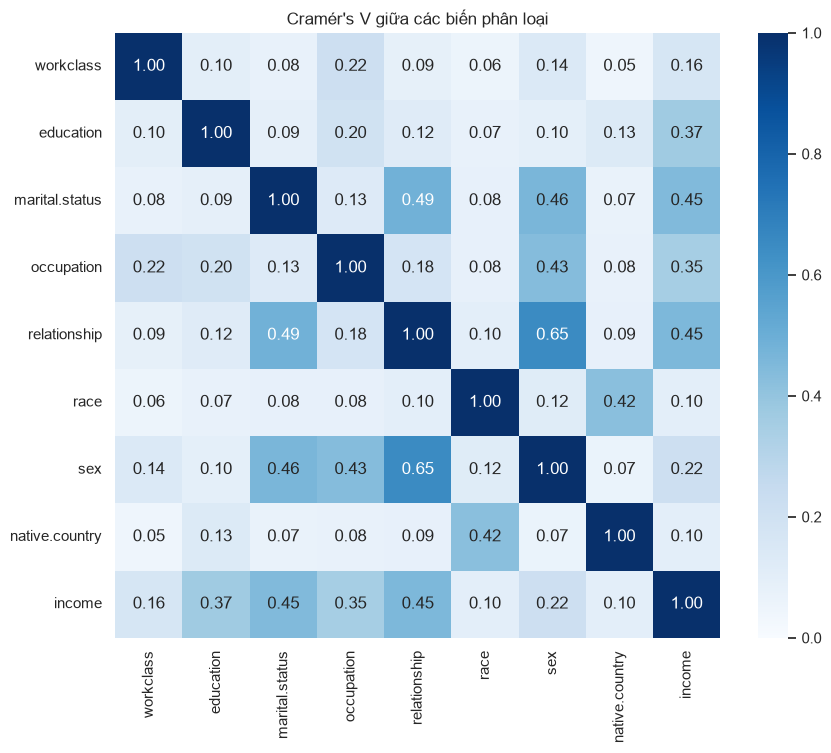

,biến 1,biến 2,Cramér's V
27,relationship,sex,0.6490
16,marital.status,relationship,0.4880
18,marital.status,sex,0.4618
29,relationship,income,0.4536
20,marital.status,income,0.4474
23,occupation,sex,0.4343


In [15]:
def cramers_v(x: pd.Series, y: pd.Series) -> float:
    table = pd.crosstab(x, y)  # crosstab tự bỏ các dòng thiếu
    chi2 = stats.chi2_contingency(table, correction=False)[0]
    n = table.values.sum()
    return float(np.sqrt(chi2 / n / (min(table.shape) - 1)))


cat_all = CAT_COLS + [TARGET]
cramers_matrix = pd.DataFrame(np.eye(len(cat_all)), index=cat_all, columns=cat_all)
for i, a in enumerate(cat_all):
    for b in cat_all[i + 1:]:
        cramers_matrix.loc[a, b] = cramers_matrix.loc[b, a] = cramers_v(adult[a], adult[b])

plt.figure(figsize=(9, 7.5))
sns.heatmap(cramers_matrix, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, square=True)
plt.title("Cramér's V giữa các biến phân loại")
plt.tight_layout()
plt.show()

cramers_pairs = corr_pairs(cramers_matrix, "Cramér's V").sort_values("Cramér's V", ascending=False)
cramers_pairs.head(6)

### Nhận xét tương quan

**Giữa các biến số, không có đa cộng tuyến.** Không có cặp nào có $\lvert r \rvert > 0.9$. Tương quan mạnh nhất chỉ là `education.num` với `hours.per.week` ($r = 0.148$, $\rho = 0.167$). Mọi VIF đều nằm trong khoảng 1,01 đến 1,04, rất xa ngưỡng 10. Các biến số gần như độc lập tuyến tính với nhau, tức mỗi biến mang một phần thông tin riêng.

**Khác biệt giữa Pearson và Spearman** lớn nhất ở cặp `age` với `hours.per.week` (0,069 so với 0,143) và cặp `age` với `capital.gain` (0,078 so với 0,125). Spearman cao gần gấp đôi, cho thấy quan hệ **đơn điệu nhưng phi tuyến**, và Pearson bị kéo thấp bởi khối giá trị 0 cùng các giá trị cực lớn của `capital.gain`. Đây là thêm một lý do để ưu tiên các phương pháp dựa trên thứ hạng với tập dữ liệu này.

**Đa cộng tuyến ẩn mà ma trận Pearson và Spearman không thấy được:**

1. **`education` và `education.num` là một.** Mỗi mức của `education` ứng với đúng một giá trị `education.num` và ngược lại (Spearman = 1,000). Nếu giữ cả hai, One-Hot của `education` sẽ là tổ hợp tuyến tính hoàn hảo của `education.num`, gây **đa cộng tuyến hoàn toàn** (VIF → ∞). **Đề xuất:** loại `education` và giữ `education.num`, vì biến này đã là dạng mã hóa thứ tự tự nhiên, chỉ cần 1 cột thay vì 16.
2. **Cụm `relationship`, `sex` và `marital.status`.** Cramér's V giữa `relationship` và `sex` là 0,649, vì giá trị `Husband` hoặc `Wife` gần như xác định giới tính. Giữa `marital.status` và `relationship` là 0,488, vì `Husband` hoặc `Wife` hàm ý `Married-civ-spouse`. Các giá trị này chưa vượt 0,9 nhưng cho thấy **dư thừa thông tin một phần**. **Đề xuất:** giữ cả ba cho mô hình cây; với mô hình tuyến tính thì dùng regularization (L2), và kiểm tra lại VIF sau khi mã hóa ở chương sau.

**Quan hệ với nhãn:** `relationship` (V = 0,454) và `marital.status` (V = 0,447) liên hệ mạnh nhất với `income`. Đây là các đặc trưng dự kiến quan trọng ở bước chọn đặc trưng.

## 4. Phân tích dữ liệu thiếu

### 4.1. Trực quan hóa bằng `missingno`

- **Matrix:** mỗi vạch trắng là một ô thiếu. Các vạch trắng nằm thẳng hàng giữa các cột cho thấy chúng thường thiếu cùng nhau.
- **Heatmap:** tương quan giữa các *chỉ báo thiếu* (nullity correlation). Giá trị gần 1 nghĩa là hai cột hầu như luôn thiếu cùng lúc.

In [16]:
missing_summary = pd.DataFrame({
    "số ô thiếu": adult.isna().sum(),
    "% thiếu": adult.isna().mean() * 100,
}).query("`số ô thiếu` > 0").sort_values("% thiếu", ascending=False)
rows_with_missing = int(adult.isna().any(axis=1).sum())
print(f"Số dòng có ít nhất một ô thiếu: {rows_with_missing:,} ({rows_with_missing / n_rows:.2%})")
missing_summary

Số dòng có ít nhất một ô thiếu: 2,399 (7.37%)


,số ô thiếu,% thiếu
occupation,1843,5.6601
workclass,1836,5.6386
native.country,583,1.7905


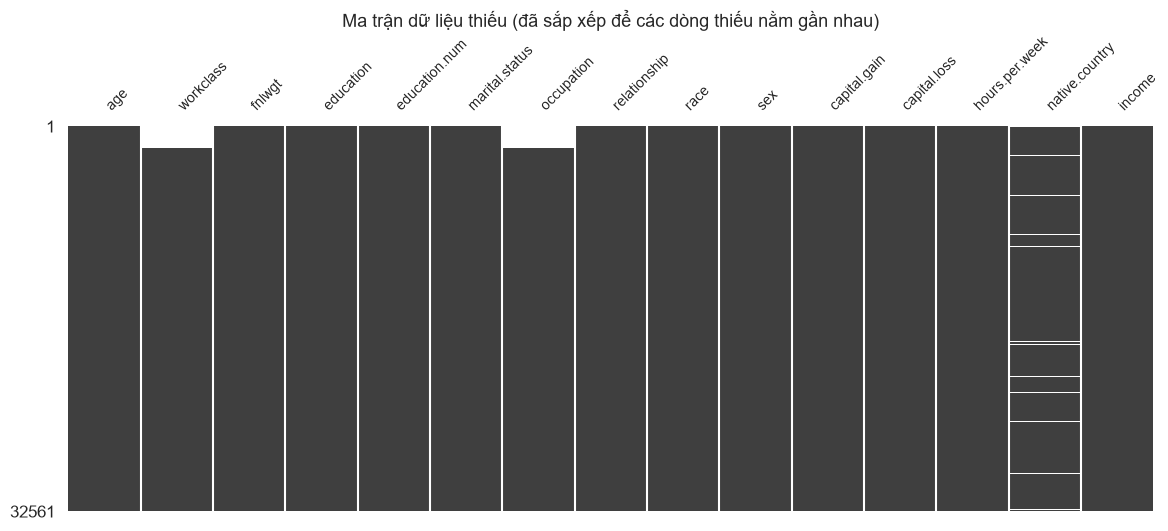

In [17]:
msno.matrix(adult.sort_values(["occupation", "workclass", "native.country"], na_position="first"),
            figsize=(14, 5), fontsize=10, sparkline=False)
plt.title("Ma trận dữ liệu thiếu (đã sắp xếp để các dòng thiếu nằm gần nhau)", fontsize=13)
plt.show()

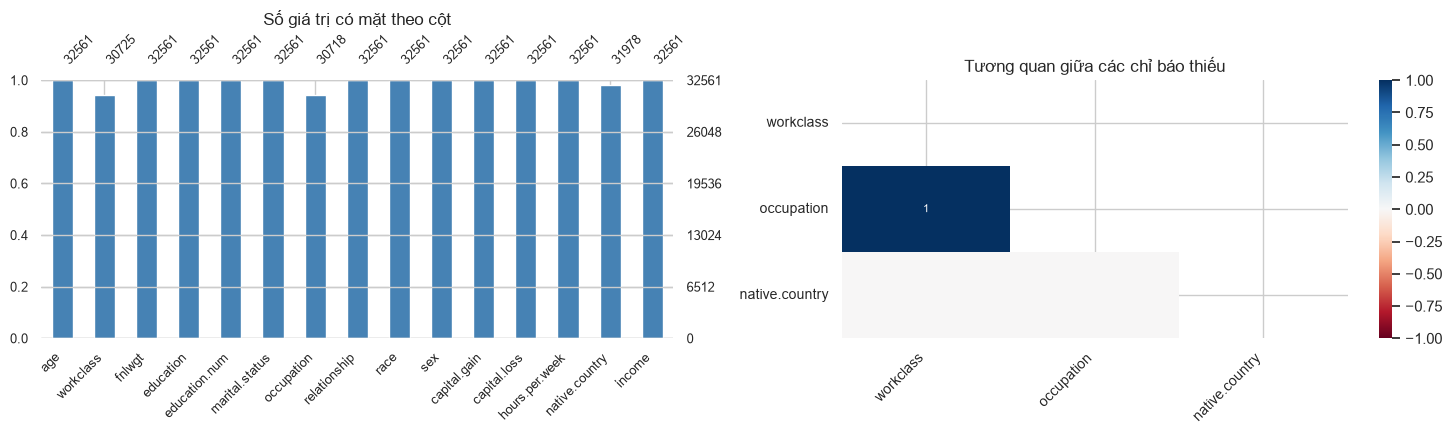

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
msno.bar(adult, ax=axes[0], fontsize=9, color="steelblue")
axes[0].set_title("Số giá trị có mặt theo cột")
msno.heatmap(adult, ax=axes[1], fontsize=10, cmap="RdBu")
axes[1].set_title("Tương quan giữa các chỉ báo thiếu")
fig.tight_layout()
plt.show()

In [19]:
missing_patterns = (
    adult[missing_summary.index].isna()
    .value_counts()
    .rename("số dòng")
    .to_frame()
)
missing_patterns["%"] = missing_patterns["số dòng"] / n_rows * 100
missing_patterns

số dòng       %
occupation workclass native.country                 
False      False     False             30162 92.6323
True       True      False              1809  5.5557
False      False     True                556  1.7076
True       True      True                 27  0.0829
           False     False                 7  0.0215

In [20]:
# Kiểm tra các dòng chỉ thiếu occupation mà không thiếu workclass
only_occ_missing = adult[adult["occupation"].isna() & adult["workclass"].notna()]
print(f"Số dòng thiếu occupation nhưng có workclass: {len(only_occ_missing)}")
print("Giá trị workclass của các dòng này:", only_occ_missing["workclass"].value_counts().to_dict())
print("Tổng số người 'Never-worked' trong dữ liệu:", int((adult["workclass"] == "Never-worked").sum()))

Số dòng thiếu occupation nhưng có workclass: 7
Giá trị workclass của các dòng này: {'Never-worked': 7}
Tổng số người 'Never-worked' trong dữ liệu: 7


### 4.2. Kiểm định Little's MCAR

#### Lý thuyết

Little (1988) đề xuất kiểm định

$$H_0: \text{dữ liệu thiếu hoàn toàn ngẫu nhiên (MCAR)}.$$

Chia các dòng thành $J$ nhóm theo **mẫu hình thiếu** (missing pattern). Nhóm $j$ có $n_j$ dòng và tập biến quan sát được $o_j$ gồm $p_j$ biến. Gọi $\hat{\mu}$ và $\hat{\Sigma}$ là ước lượng hợp lý cực đại (ML) của vector kỳ vọng và ma trận hiệp phương sai trên toàn bộ dữ liệu, tính bằng **thuật toán EM**. Thống kê kiểm định là

$$d^2 = \sum_{j=1}^{J} n_j \left(\bar{y}_{o_j} - \hat{\mu}_{o_j}\right)^{\top} \hat{\Sigma}_{o_j o_j}^{-1} \left(\bar{y}_{o_j} - \hat{\mu}_{o_j}\right) \;\sim\; \chi^2_{\,\sum_j p_j - p} \text{ dưới } H_0.$$

Ý tưởng: nếu dữ liệu là MCAR thì trung bình của các biến quan sát được trong mỗi nhóm không được lệch có hệ thống so với trung bình chung.

**Thuật toán EM** cho phân phối chuẩn nhiều chiều có dữ liệu thiếu lặp lại hai bước. Với mỗi dòng có phần quan sát được $o$ và phần thiếu $m$:

- **Bước E:** điền kỳ vọng có điều kiện $\hat{x}_m = \mu_m + \Sigma_{mo}\Sigma_{oo}^{-1}(x_o - \mu_o)$ và cộng thêm phần hiệp phương sai có điều kiện $\Sigma_{mm} - \Sigma_{mo}\Sigma_{oo}^{-1}\Sigma_{om}$ vào moment bậc hai.
- **Bước M:** cập nhật $\mu$ và $\Sigma$ từ các moment kỳ vọng.

#### Cách áp dụng cho Adult

Kiểm định Little được xây dựng cho biến số, trong khi cả ba cột có giá trị thiếu (`workclass`, `occupation`, `native.country`) đều là biến phân loại. Cách xử lý:

- Ba cột này được **mã hóa tần suất** (thay mỗi giá trị bằng tỷ lệ xuất hiện của nó). Ô thiếu vẫn giữ là `NaN`.
- Đưa thêm 6 biến số và nhãn `income` (0/1) vào kiểm định.

Mã hóa tần suất không đòi hỏi thứ tự giả tạo giữa các mức. Tuy vậy, kiểm định vẫn dựa trên giả định chuẩn nhiều chiều, nên kết quả cần được đối chiếu với các phân tích bổ trợ ở mục 4.3.

SciPy và statsmodels không có sẵn kiểm định này, nên phần cài đặt dưới đây được viết trực tiếp từ công thức.

In [21]:
def em_mvn(X: np.ndarray, max_iter: int = 500, tol: float = 1e-8):
    # Ước lượng ML (mu, Sigma) của phân phối chuẩn nhiều chiều khi X có NaN, bằng thuật toán EM.
    n, p = X.shape
    miss = np.isnan(X)
    mu = np.nanmean(X, axis=0)
    sigma = np.diag(np.nanvar(X, axis=0))
    patterns, inverse = np.unique(miss, axis=0, return_inverse=True)
    inverse = inverse.ravel()

    for it in range(max_iter):
        sum_x = np.zeros(p)
        sum_xx = np.zeros((p, p))
        for k, pat in enumerate(patterns):
            rows = X[inverse == k]
            o, m = ~pat, pat
            x_hat = rows.copy()
            cond_cov = np.zeros((p, p))
            if m.any():
                s_oo_inv = np.linalg.inv(sigma[np.ix_(o, o)])
                beta = sigma[np.ix_(m, o)] @ s_oo_inv  # hệ số hồi quy x_m theo x_o
                x_hat[:, m] = mu[m] + (rows[:, o] - mu[o]) @ beta.T
                cond_cov[np.ix_(m, m)] = sigma[np.ix_(m, m)] - beta @ sigma[np.ix_(o, m)]
            sum_x += x_hat.sum(axis=0)
            sum_xx += x_hat.T @ x_hat + len(rows) * cond_cov
        mu_new = sum_x / n
        sigma_new = sum_xx / n - np.outer(mu_new, mu_new)
        converged = np.max(np.abs(mu_new - mu)) < tol and np.max(np.abs(sigma_new - sigma)) < tol
        mu, sigma = mu_new, sigma_new
        if converged:
            break
    return mu, sigma, it + 1


def little_mcar_test(df: pd.DataFrame) -> dict:
    # Kiểm định Little's MCAR (1988). Trả về thống kê d², bậc tự do và p-value.
    X = df.to_numpy(dtype=float)
    # Chuẩn hóa để EM ổn định số học; d² không đổi qua phép biến đổi affine
    X = (X - np.nanmean(X, axis=0)) / np.nanstd(X, axis=0)
    mu, sigma, n_iter = em_mvn(X)
    miss = np.isnan(X)
    patterns, inverse = np.unique(miss, axis=0, return_inverse=True)
    inverse = inverse.ravel()

    d2, dof = 0.0, 0
    for k, pat in enumerate(patterns):
        o = ~pat
        if not o.any():
            continue
        rows = X[inverse == k][:, o]
        diff = rows.mean(axis=0) - mu[o]
        d2 += len(rows) * diff @ np.linalg.solve(sigma[np.ix_(o, o)], diff)
        dof += int(o.sum())
    dof -= X.shape[1]
    return {"d2": float(d2), "dof": dof, "p_value": float(stats.chi2.sf(d2, dof)),
            "n_patterns": len(patterns), "em_iterations": n_iter}

In [22]:
mcar_input = adult[NUM_COLS].astype(float).copy()
for col in missing_summary.index:
    freq = adult[col].value_counts(normalize=True)
    mcar_input[col] = adult[col].map(freq).astype(float)  # NaN được giữ nguyên
mcar_input["income"] = (adult[TARGET] == ">50K").astype(float)

little_result = little_mcar_test(mcar_input)
little_d2, little_dof, little_p = little_result["d2"], little_result["dof"], little_result["p_value"]
print(f"Số mẫu hình thiếu       : {little_result['n_patterns']}")
print(f"Số vòng lặp EM          : {little_result['em_iterations']}")
print(f"Thống kê d²             : {little_d2:,.2f}")
print(f"Bậc tự do               : {little_dof}")
print(f"p-value                 : {little_p:.3e}")
print("Kết luận:", "bác bỏ H0, dữ liệu KHÔNG phải MCAR" if little_p < ALPHA else "chưa đủ bằng chứng bác bỏ MCAR")

Số mẫu hình thiếu       : 5
Số vòng lặp EM          : 10
Thống kê d²             : 1,284.08
Bậc tự do               : 33
p-value                 : 9.529e-249
Kết luận: bác bỏ H0, dữ liệu KHÔNG phải MCAR


#### Kiểm tra tính đúng đắn của cài đặt

Một kiểm định được cài đặt đúng phải giữ được mức sai lầm loại I. Ta tạo dữ liệu có cùng cấu trúc nhưng **xóa ngẫu nhiên hoàn toàn (MCAR thật)** với cùng tỷ lệ thiếu, rồi lặp lại kiểm định nhiều lần. Dưới $H_0$, p-value phải phân phối đều trên $[0, 1]$, nghĩa là khoảng 5% số lần lặp có $p < 0.05$.

In [23]:
rng = np.random.default_rng(RANDOM_STATE)
complete_rows = mcar_input.dropna()
sim_pvalues = []
for _ in range(100):
    sim = complete_rows.sample(n=5000, random_state=int(rng.integers(1e9))).reset_index(drop=True)
    for col in missing_summary.index:
        mask = rng.random(len(sim)) < adult[col].isna().mean()
        sim.loc[mask, col] = np.nan
    sim_pvalues.append(little_mcar_test(sim)["p_value"])
sim_pvalues = np.array(sim_pvalues)
sim_type1_error = float((sim_pvalues < ALPHA).mean())
sim_ks_uniform = stats.kstest(sim_pvalues, "uniform").pvalue
print(f"Tỷ lệ bác bỏ H0 khi dữ liệu thật sự MCAR: {sim_type1_error:.2%} (kỳ vọng ≈ 5%)")
print(f"KS test p-value đều trên [0, 1]: p = {sim_ks_uniform:.3f}")

Tỷ lệ bác bỏ H0 khi dữ liệu thật sự MCAR: 7.00% (kỳ vọng ≈ 5%)
KS test p-value đều trên [0, 1]: p = 0.026


### Nhận xét kiểm định Little's MCAR

- Dữ liệu có **5 mẫu hình thiếu**. Thuật toán EM hội tụ sau 10 vòng lặp.
- Thống kê $d^2 = 1284{,}08$ với 33 bậc tự do, cho $p \approx 9.5\times10^{-249} \ll 0.05$. **Bác bỏ $H_0$: dữ liệu thiếu không phải MCAR.**

**Độ tin cậy của cài đặt:** khi dữ liệu thật sự là MCAR (mô phỏng), tỷ lệ bác bỏ sai là 7%, gần với mức danh nghĩa 5%. Kiểm định KS về tính đều của p-value cho $p = 0.026$, cho thấy kiểm định **hơi dễ dãi** (liberal) trên dữ liệu này. Nguyên nhân hợp lý là kiểm định Little giả định phân phối chuẩn nhiều chiều, trong khi `capital.gain` và `capital.loss` có đuôi cực dài (mục 2), còn mã hóa tần suất tạo ra biến rời rạc.

Tuy vậy, kết luận vẫn vững vì hai lý do. Thứ nhất, kỳ vọng của $\chi^2_{33}$ chỉ là 33, trong khi $d^2$ lớn gấp khoảng 39 lần. Một độ lệch nhỏ của mức ý nghĩa không thể giải thích được khoảng cách này. Thứ hai, các phân tích bổ trợ ở mục 4.3 (không dựa trên giả định chuẩn) cho cùng kết luận.

### 4.3. Phân tích bổ trợ: tính thiếu phụ thuộc vào biến nào?

Little's test chỉ trả lời câu hỏi *có phải MCAR hay không*. Để phân biệt **MAR** với **MNAR**, ta xem tính thiếu có liên hệ với các biến **quan sát được** hay không:

- Với mỗi cột có giá trị thiếu, tạo chỉ báo $M = \mathbb{1}[\text{ô bị thiếu}]$.
- So sánh các biến số giữa nhóm thiếu ($M=1$) và nhóm có dữ liệu ($M=0$) bằng **Mann-Whitney U**. Đây là kiểm định phi tham số, phù hợp vì các biến không chuẩn (mục 2). Kèm theo là độ lớn hiệu ứng **rank-biserial** $r_{rb} = 1 - \dfrac{2U}{n_1 n_0}$.
- Kiểm định quan hệ giữa $M$ với biến phân loại và với `income` bằng **$\chi^2$ độc lập**, kèm Cramér's V.

In [24]:
mar_rows = []
for miss_col in missing_summary.index:
    m = adult[miss_col].isna()
    for col in NUM_COLS:
        a, b = adult.loc[m, col], adult.loc[~m, col]
        u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
        mar_rows.append({"cột thiếu": miss_col, "biến": col, "kiểm định": "Mann-Whitney",
                         "median (thiếu)": a.median(), "median (có)": b.median(),
                         "hiệu ứng": 1 - 2 * u / (len(a) * len(b)), "p-value": p})
    for col in [c for c in cat_all if c not in missing_summary.index]:
        table = pd.crosstab(m, adult[col])
        chi2, p, *_ = stats.chi2_contingency(table)
        mar_rows.append({"cột thiếu": miss_col, "biến": col, "kiểm định": "Chi-square",
                         "hiệu ứng": np.sqrt(chi2 / table.values.sum() / (min(table.shape) - 1)), "p-value": p})
mar_tests = pd.DataFrame(mar_rows)
mar_tests["có ý nghĩa"] = mar_tests["p-value"] < ALPHA
mar_tests["|hiệu ứng|"] = mar_tests["hiệu ứng"].abs()

print("Số kiểm định có ý nghĩa thống kê theo từng cột thiếu:")
print(mar_tests.groupby("cột thiếu")["có ý nghĩa"].agg(["sum", "count"]).to_string())
mar_tests.sort_values("|hiệu ứng|", ascending=False).drop(columns="|hiệu ứng|").head(12)

Số kiểm định có ý nghĩa thống kê theo từng cột thiếu:
                sum  count
cột thiếu                 
native.country    7     12
occupation       10     12
workclass        10     12


,cột thiếu,biến,kiểm định,median (thiếu),median (có),hiệu ứng,p-value,có ý nghĩa
5,occupation,hours.per.week,Mann-Whitney,36.0000,40.0000,0.3824,0.0000,True
17,workclass,hours.per.week,Mann-Whitney,36.0000,40.0000,0.3818,0.0000,True
2,occupation,education.num,Mann-Whitney,9.0000,10.0000,0.1688,0.0000,True
14,workclass,education.num,Mann-Whitney,9.0000,10.0000,0.1673,0.0000,True
26,native.country,education.num,Mann-Whitney,10.0000,10.0000,-0.1308,0.0000,True
8,occupation,relationship,Chi-square,NaN,NaN,0.1059,0.0000,True
20,workclass,relationship,Chi-square,NaN,NaN,0.1046,0.0000,True
33,native.country,race,Chi-square,NaN,NaN,0.0997,0.0000,True
6,occupation,education,Chi-square,NaN,NaN,0.0969,0.0000,True
7,occupation,marital.status,Chi-square,NaN,NaN,0.0963,0.0000,True


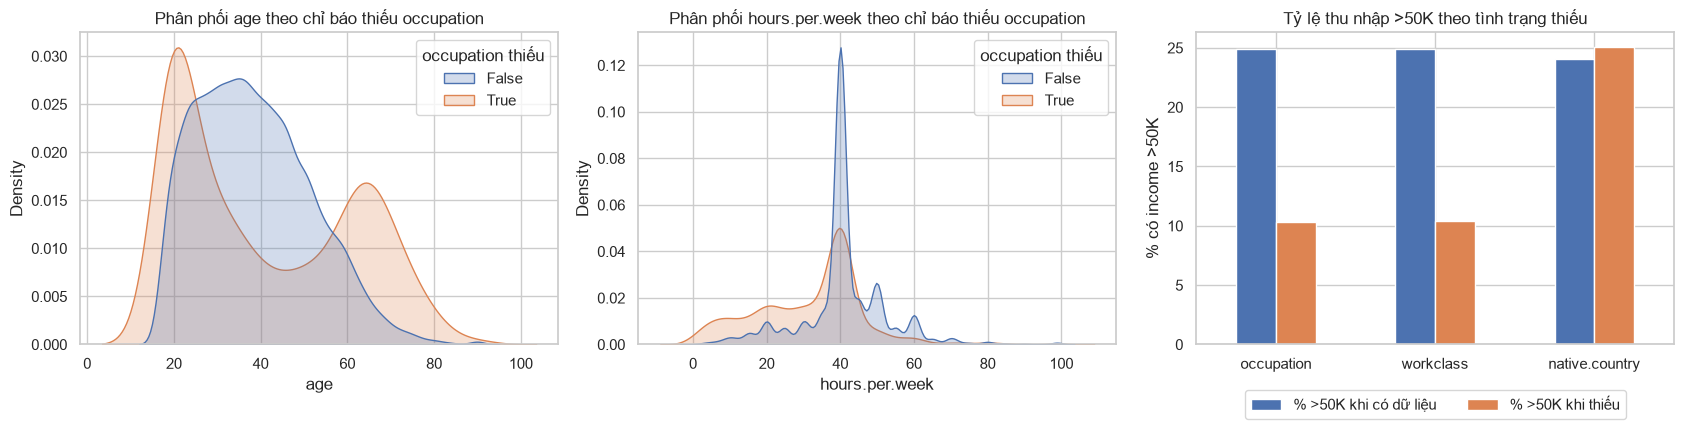

,% >50K khi có dữ liệu,% >50K khi thiếu
occupation,24.9040,10.3635
workclass,24.8983,10.4031
native.country,24.0634,25.0429


In [25]:
income_by_missing = pd.DataFrame({
    col: adult.groupby(adult[col].isna())[TARGET].apply(lambda s: (s == ">50K").mean())
    for col in missing_summary.index
}).T.rename(columns={False: "% >50K khi có dữ liệu", True: "% >50K khi thiếu"}) * 100

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
plot_df = adult.assign(**{"occupation thiếu": adult["occupation"].isna()})
sns.kdeplot(data=plot_df, x="age", hue="occupation thiếu", common_norm=False, fill=True, ax=axes[0])
axes[0].set_title("Phân phối age theo chỉ báo thiếu occupation")
sns.kdeplot(data=plot_df, x="hours.per.week", hue="occupation thiếu", common_norm=False, fill=True, ax=axes[1])
axes[1].set_title("Phân phối hours.per.week theo chỉ báo thiếu occupation")
income_by_missing.plot.bar(ax=axes[2], rot=0)
axes[2].legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
axes[2].set_ylabel("% có income >50K")
axes[2].set_title("Tỷ lệ thu nhập >50K theo tình trạng thiếu")
fig.tight_layout()
plt.show()
income_by_missing

In [26]:
occ_missing = adult["occupation"].isna()
age_groups_by_missing = pd.DataFrame({
    "% dưới 25 tuổi": [(adult.loc[occ_missing, "age"] < 25).mean(), (adult["age"] < 25).mean()],
    "% từ 60 tuổi": [(adult.loc[occ_missing, "age"] >= 60).mean(), (adult["age"] >= 60).mean()],
}, index=["thiếu occupation", "toàn bộ dữ liệu"]) * 100
print(age_groups_by_missing.round(2).to_string())

race_by_country_missing = pd.crosstab(adult["race"], adult["native.country"].isna(), normalize="columns") * 100
race_by_country_missing.columns = ["% khi có native.country", "% khi thiếu native.country"]
race_by_country_missing.round(2)

                  % dưới 25 tuổi  % từ 60 tuổi
thiếu occupation         34.6200       28.4300
toàn bộ dữ liệu          17.1100        8.1200


,% khi có native.country,% khi thiếu native.country
race,,
Amer-Indian-Eskimo,0.9700,0.0000
Asian-Pac-Islander,2.9900,14.2400
Black,9.4700,16.4700
Other,0.7900,3.0900
White,85.7800,66.2100


### Nhận xét cơ chế thiếu

**1. `workclass` và `occupation` thiếu cùng nhau** (tương quan chỉ báo thiếu bằng 1). 1836 dòng thiếu cả hai. 7 dòng chỉ thiếu `occupation` đều có `workclass = Never-worked`, và đây cũng chính là toàn bộ 7 người `Never-worked` trong dữ liệu. Với những người này, `occupation` **không tồn tại** chứ không phải bị thiếu (thiếu cấu trúc), nên có thể điền thẳng một mức riêng như `None` mà không cần ước lượng.

**2. Việc thiếu `workclass` và `occupation` liên hệ chặt với các biến quan sát được:**

- **Tuổi:** nhóm thiếu `occupation` có phân phối tuổi **hai đỉnh** quanh 20 và 65 tuổi. 34,6% nhóm này dưới 25 tuổi (toàn bộ dữ liệu: 17,1%), và 28,4% từ 60 tuổi trở lên (toàn bộ dữ liệu: 8,1%). Kết hợp với `relationship = Own-child` chiếm 29,5% nhóm thiếu, hình ảnh hiện ra là **sinh viên** và **người đã nghỉ hưu**.
- **Số giờ làm:** median 36 giờ so với 40 giờ, và đây là hiệu ứng lớn nhất trong mọi kiểm định ($r_{rb} = 0.38$).
- **Học vấn:** thấp hơn (median `education.num` là 9 so với 10).
- **Thu nhập:** chỉ 10,4% nhóm thiếu có thu nhập >50K, so với 24,9% ở nhóm có dữ liệu.

Xác suất thiếu phụ thuộc vào các biến quan sát được, nên cơ chế **không phải MCAR mà ít nhất là MAR**. Có thể có thêm thành phần **MNAR**: người không có việc làm ổn định (thất nghiệp, nghỉ hưu, đi học) bỏ trống chính câu hỏi về nghề nghiệp. Khi đó, việc thiếu phụ thuộc vào *giá trị của chính biến bị thiếu*. Không thể kiểm chứng MNAR chỉ từ dữ liệu quan sát được, nhưng phân phối tuổi hai đỉnh rất khớp với giải thích này.

**3. `native.country` (1,79% thiếu) gần với MCAR hơn.** 7 trên 12 kiểm định có ý nghĩa, nhưng hiệu ứng đều nhỏ: $\lvert r_{rb} \rvert \le 0.13$, Cramér's V $\le 0.10$. Tỷ lệ thu nhập >50K gần như không đổi (25,0% so với 24,1%). Liên hệ đáng kể nhất là với `race`: tỷ lệ `Asian-Pac-Islander` trong nhóm thiếu là 14,2%, so với 3,0% ở nhóm có dữ liệu. Điều này có thể đến từ người nhập cư không khai quốc tịch gốc. Ta xếp `native.country` vào **MAR yếu**, có quan hệ với `race`.

| Cột | % thiếu | Cơ chế | Căn cứ chính |
|---|---|---|---|
| `workclass` | 5,64 | MAR, có thể có thành phần MNAR | Little's test, tuổi hai đỉnh, giờ làm thấp, thu nhập thấp |
| `occupation` | 5,66 | MAR, có thể có thành phần MNAR (7 dòng thiếu cấu trúc) | Như trên, cộng với `Never-worked` |
| `native.country` | 1,79 | MAR yếu, gần MCAR | Hiệu ứng nhỏ, liên hệ với `race` |

## 5. Tổng kết và định hướng cho chương tiền xử lý

| Phát hiện từ EDA | Hệ quả cho chương tiền xử lý |
|---|---|
| Không thuộc tính số nào có phân phối chuẩn; `capital.*` dồn khối tại 0 và có IQR = 0 | Không dùng Z-score làm mặc định. Dùng Min-Max cho `age` và `education.num`, Robust Scaling cho `fnlwgt`, $\log(1+x)$ kèm biến nhị phân cho `capital.*`. Kiểm chứng bằng Levene và violin plot |
| `hours.per.week` có IQR rất hẹp (40 đến 45) | So sánh Robust Scaling với Quantile Transform. Không coi 27,7% giá trị ngoài khoảng IQR là ngoại lai |
| 159 dòng có `capital.gain = 99999` (giá trị trần), 100% thu nhập >50K | Ngoại lai *có thông tin*: so sánh kết quả khi giữ và khi loại, đo bằng KS test |
| `education` và `education.num` trùng thông tin hoàn toàn | Loại `education` |
| Cụm `relationship`, `sex`, `marital.status` dư thừa một phần (V từ 0,46 đến 0,65) | Kiểm tra VIF sau khi mã hóa; dùng regularization cho mô hình tuyến tính |
| `native.country` có 41 mức nhưng 91% là `United-States` | Phù hợp để thử Binary Encoding và Frequency Encoding |
| Dữ liệu thiếu không phải MCAR mà là MAR (có thể có thêm MNAR) | Ưu tiên phương pháp điền dựa trên biến khác (kNN, MICE) thay vì mean hoặc mode. Thêm biến chỉ báo thiếu cho `workclass` và `occupation`. Điền `Never-worked` → `occupation = None` |
| 24 dòng trùng lặp | Loại bỏ trước khi chia train/test |
| `fnlwgt` là trọng số mẫu, không liên quan đến nhãn | Ứng viên loại ở bước chọn đặc trưng |
| Nhãn mất cân bằng 3,15 : 1 | Chia train/test có phân tầng. Đánh giá bằng F1-macro và AUC. Resample chỉ trên tập train |